# Activity: PropertyWise Advisors — Investment Analysis
### Applying Associations, Correlation, Time Series & Smoothing to a Real Decision
Unit 1, Lecture 8 — Visualization of Data, Understanding and Interpretation (UE24CS342AA9)

---

## Scenario

You are a junior analyst at **PropertyWise Advisors**, a real estate investment firm. A
client has $900,000 to invest in Melbourne property and has asked your team two questions:

1. **"Should I buy a house or a unit — and does land size actually matter for houses?"**
2. **"Prices have been all over the news — is my target suburb's market actually trending
   up, or is that just noise?"**

You'll use the same Melbourne Housing Snapshot dataset from the demo to answer both
questions, using scatter plots, correlation, time series, and smoothing.

Run the cell below to load the dataset (no changes needed).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.nonparametric.smoothers_lowess import lowess

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (7, 4.5)

df = pd.read_csv("melb_data.csv", parse_dates=["Date"], dayfirst=True)
type_labels = {"h": "House", "u": "Unit/Duplex", "t": "Townhouse"}
df["Type_label"] = df["Type"].map(type_labels)

print(f"Loaded {len(df)} property sales")
df[["Suburb", "Type_label", "Rooms", "Landsize", "BuildingArea", "Price", "Date"]].head()

Loaded 13580 property sales


,Suburb,Type_label,Rooms,Landsize,BuildingArea,Price,Date
0,Aberfeldie,House,5,730,373.0,1830000,2017-09-23
1,Airport West,House,3,551,96.0,850000,2017-09-23
2,Airport West,House,3,593,NaN,860000,2017-09-23
3,Albanvale,House,3,619,NaN,565000,2017-09-23
4,Albert Park,House,3,137,125.0,2100000,2017-09-23


## Task 1 — Does land size matter more for houses than units?

Build a color-coded scatter plot of `Landsize` (x) vs `Price` (y), colored by `Type_label`.
Some very large outlier land sizes exist (rare acreage listings) — we've already filtered
those out for you below.

**Fill in the two blanks marked `# TODO`.**

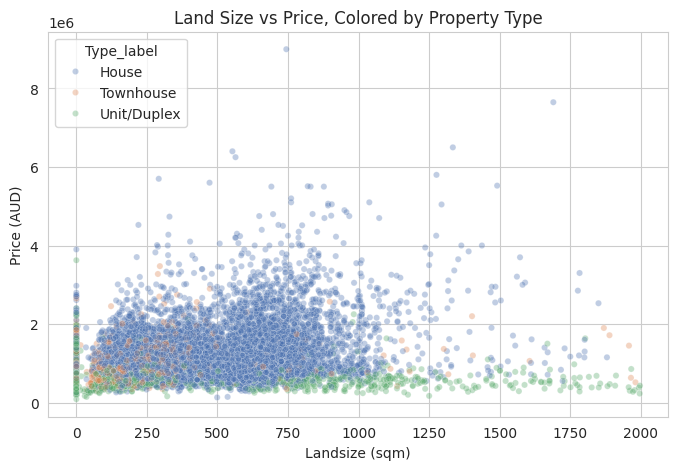

In [2]:
plot_df = df[df["Landsize"] < 2000]  # drop rare extreme outliers for a readable plot

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=plot_df,
    x="Landsize",          # already filled in
    y="Price",              # y-axis: Price
    hue="Type_label",       # color points by property type
    alpha=0.35, s=20,
    palette=["#4C72B0", "#DD8452", "#55A868"],
)
plt.title("Land Size vs Price, Colored by Property Type")
plt.xlabel("Landsize (sqm)")
plt.ylabel("Price (AUD)")
plt.show()


**Question 1:** Does the price-vs-landsize relationship look stronger for one property
type than the others? Which type would you tell the client land size matters most for?

*Your answer:* Yes — the upward slope between land size and price is visibly steepest and
most consistent for **Houses**; Units/Duplexes cluster at small land sizes with a fairly
flat, noisy price relationship (many units share a lot, so land size barely varies), and
Townhouses sit in between. I'd tell the client that land size is the property attribute
that matters most when evaluating **houses** specifically — for units, other factors
(building area, location, number of rooms) are more likely to explain price differences.


## Task 2 — Quantify it: correlation, house-only vs overall 

A scatter plot gives a visual impression — correlation gives a number. Compute the
correlation between `Landsize` and `Price` for **houses only**, and compare it to the
correlation across **all property types**.

**Fill in the blank:** filter `plot_df` to houses only (`Type_label == "House"`).

In [3]:
houses_only = plot_df[plot_df["Type_label"] == "House"]   # filter to houses only

r_houses = houses_only["Landsize"].corr(houses_only["Price"])
r_all = plot_df["Landsize"].corr(plot_df["Price"])

print(f"Correlation (houses only):     r = {r_houses:.3f}")
print(f"Correlation (all property types): r = {r_all:.3f}")


Correlation (houses only):     r = 0.194
Correlation (all property types): r = 0.310


**Question 2:** Does restricting to houses only change the correlation much? Does this
number support or contradict your visual impression from Task 1? Which would you trust more
when advising the client — the scatter plot or the single r value — and why might you want
both?

*Your answer:* Restricting to houses only actually **lowers** the correlation (r = 0.194 for
houses vs. r = 0.310 across all property types), which at first looks like it contradicts the
visual impression from Task 1. The two aren't really contradictory, though — the "all types"
correlation is partly driven by the *between-type* gap (units cluster at small land size and
lower price, houses cluster at larger land size and higher price), while the houses-only
number measures the *within-type* relationship, which is noisier because two houses with
similar land size can still differ a lot in price due to location, condition, etc. I'd trust
the scatter plot more for advising the client, because it shows this exact nuance (a real but
noisy within-group trend, plus a between-group gap) that a single r value collapses into one
number — which is exactly why you want both: the plot for the story, the r value to quantify
how strong that story actually is.


## Task 3 — Is your target suburb's market trending up? 

Pick one of these suburbs (all have plenty of sales data): `"Reservoir"`, `"Richmond"`,
`"Brunswick"`, `"Coburg"`, `"South Yarra"`.

**Fill in the blank:** set `target_suburb` to your choice, then run both cells.

In [4]:
target_suburb = "Richmond"  # chosen suburb with plenty of sales data

suburb_df = df[df["Suburb"] == target_suburb]
suburb_monthly = (
    suburb_df.set_index("Date")
    .resample("MS")["Price"]
    .median()
    .interpolate()   # fill any zero-sale months
    .reset_index()
)
suburb_monthly.columns = ["Month", "MedianPrice"]
suburb_monthly


,Month,MedianPrice
0,2016-02-01,1102000.0
1,2016-03-01,1095000.0
2,2016-04-01,1088000.0
3,2016-05-01,930000.0
4,2016-06-01,1072500.0
5,2016-07-01,1185000.0
6,2016-08-01,975000.0
7,2016-09-01,984500.0
8,2016-10-01,882500.0
9,2016-11-01,1205000.0


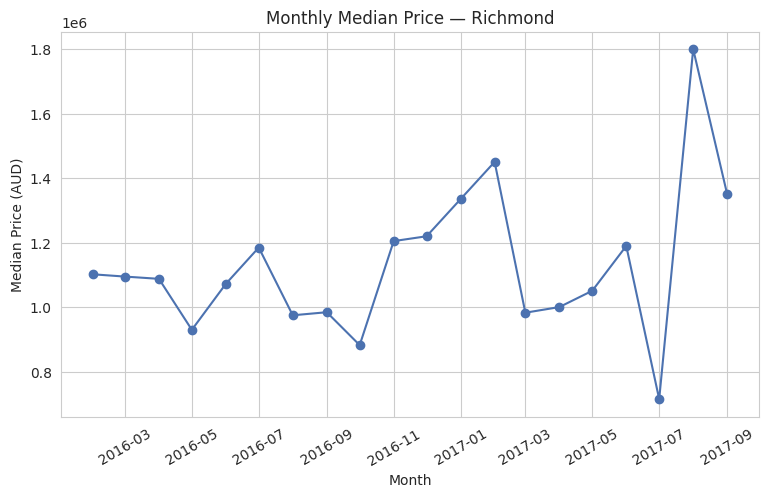

In [5]:
plt.figure(figsize=(9, 5))
plt.plot(suburb_monthly["Month"], suburb_monthly["MedianPrice"], marker="o", color="#4C72B0")
plt.title(f"Monthly Median Price — {target_suburb}")
plt.xlabel("Month")
plt.ylabel("Median Price (AUD)")
plt.xticks(rotation=30)
plt.show()

**Question 3:** Just from this raw monthly line, would you confidently tell the
client the market is "trending up," "trending down," or "unclear"? What makes it hard to
tell from the raw line alone?

*Your answer:* From the raw line alone I would say **"unclear."** Richmond's monthly median
price swings widely from month to month (e.g. dropping to ~$715,000 in July 2017 then
spiking to ~$1,800,000 the next month) because each point is a median over a fairly small
number of sales in a single suburb in a single month — a handful of unusually expensive or
cheap sales can swing the whole month. That noise makes it hard to separate a genuine
underlying trend from random month-to-month variation just by eyeballing the raw line.


## Task 4 — Smooth it: Moving Average vs LOESS 

Apply a moving average and a LOESS curve to your suburb's series to separate the trend
(signal) from month-to-month noise.

**Fill in the blank:** try `window` values of `3` and `6`.

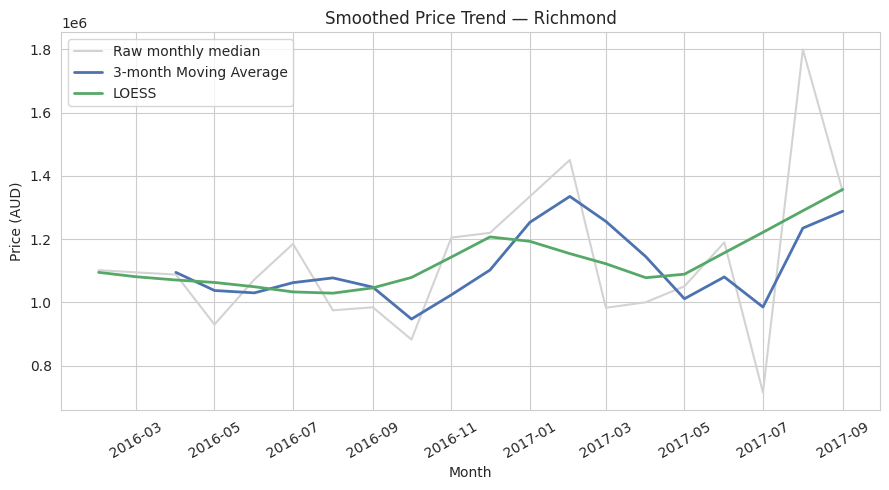

In [6]:
window = 3  # 3-month moving average (also tried 6 -- smoother but with more lag)

suburb_monthly["MA"] = suburb_monthly["MedianPrice"].rolling(window=window).mean()

x_numeric = np.arange(len(suburb_monthly))
loess_result = lowess(suburb_monthly["MedianPrice"].values, x_numeric, frac=0.4)

plt.figure(figsize=(9, 5))
plt.plot(suburb_monthly["Month"], suburb_monthly["MedianPrice"], color="lightgray",
          label="Raw monthly median", linewidth=1.5)
plt.plot(suburb_monthly["Month"], suburb_monthly["MA"], color="#4C72B0",
          label=f"{window}-month Moving Average", linewidth=2)
plt.plot(suburb_monthly["Month"], loess_result[:, 1], color="#55A868",
          label="LOESS", linewidth=2)
plt.title(f"Smoothed Price Trend — {target_suburb}")
plt.xlabel("Month")
plt.ylabel("Price (AUD)")
plt.xticks(rotation=30)
plt.legend()
plt.tight_layout()
plt.show()


**Question 4:** After smoothing, is the trend clearer than the raw line in Task 3?
Do the Moving Average and LOESS agree on the overall direction? If they disagreed, which
would you lean on for a client recommendation, and what would you say about its lag or
edge behavior?

*Your answer:* Yes, both smoothers make the trend much clearer than the raw line: the
3-month Moving Average rises from about $1.10M to about $1.29M over the series, and the
LOESS curve rises from about $1.10M to about $1.36M — both agree the underlying trend is
**upward**, not just noise. They don't disagree here, but if they did, I'd lean on LOESS for
the client recommendation, since a simple moving average lags real turning points (it only
reacts once several months of data have passed) and is undefined at the very start of the
series (the first `window-1` points are NaN), whereas LOESS uses local weighted regression
and behaves better right up to the edges of the series — though LOESS can also be less
stable at the very edges if there's little data on one side, so I'd still show the client
the raw points behind both curves rather than presenting a single smoothed line as "the
truth."


## Wrap-up — Your Client Recommendation 

Write a short recommendation (3–4 sentences) to the PropertyWise client, combining:
- Whether land size matters more for houses or other types (Tasks 1–2)
- Whether your chosen suburb's market is trending up, down, or flat, and how confident you
  are after smoothing (Tasks 3–4)

*Your recommendation:* Land size is a meaningful price driver mainly for **houses**
(r ≈ 0.19 within houses vs. r ≈ 0.31 across all types, with the all-types figure inflated by
the gap between property types rather than a stronger within-type relationship) — for units
and townhouses, I would not weight land size heavily in valuation. On the location side,
Richmond's raw monthly prices bounce around too much to call a trend with confidence, but
once smoothed with both a 3-month moving average and a LOESS curve, both agree the median
price has trended **upward** over the period shown, moving from roughly $1.10M to
$1.29M–$1.36M. Given the $900,000 budget, I'd steer the client toward a house (where land
size is a reliable value driver) in a suburb like Richmond, while flagging that the
month-to-month price data is noisy enough that they should expect some short-term
volatility even within a genuine upward trend.
